# Lab 10: How to draw, pause and resume an agent with LangGraph

**Notebook 1 of 2: meet LangGraph on a pizza order**

## Goal

Write a small pizza-ordering program as a LangGraph **graph**, with no model in it at first. A graph has a state
that every step can read, nodes that each do one job, and edges that say which node runs next. We watch two nodes
write to the same list and one wipe out the other's work, and fix it with a reducer. We send big orders down
another path, stop the program in the middle to ask the customer a question, and carry on when the answer comes.
Only then does one node become a model call, and we find the same kind of graph inside a ready-made agent. This
notebook is the playground; notebook 2 builds the agent of the Chinook support desk as a graph.

## What you will learn

- How to write a program as a graph (a state, nodes that return updates, and edges), draw it, and watch it run
  step by step.
- Why a node's update replaces a value by default, and how a reducer lets two nodes add to the same list.
- How to choose the next node in our own code with a conditional edge.
- How to pause a run inside a node with `interrupt`, where the paused run is kept (a checkpointer and a thread
  id), and how to resume it with `Command`.
- How to make one node a model call, and how to recognise the model node and the tools node of an agent built
  with `create_agent`.

## Setup

The first cell is the same in every lab: it finds the repository folder, reads the model name from `models.env`,
and takes the key from `.env` without printing it. Parts A to D call no model. The key is first used in Part E.

In [1]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


---

## Part A: Write a program as a graph with a state, nodes and edges

A pizza place handles an order in three steps: start the pizza, work out the price, send the order to the kitchen.
We write the three steps as plain Python functions and run them ourselves. Then we hand the same functions to
LangGraph and see what it adds.

### The order, and three functions that each do one step

The order is a dictionary. It starts with what the customer chose:

```python
{"size": "medium", "extras": []}
```

Each function takes the order and **returns only what it adds**, as a small dictionary:

- `take_order` starts the pizza. Every pizza gets tomato sauce and mozzarella.
- `price` works out the price: a base price for the size, plus 1.50 dollars for each extra topping.
- `place_order` sends the order to the kitchen. Its first line prints `ORDER PLACED`. That print is how we will
  know, for the rest of this notebook, that an order really went to the kitchen.

In [2]:
BASE_PRICE = {"small": 8.00, "medium": 11.00, "large": 14.00}
EXTRA_PRICE = 1.50


def take_order(order):
    return {"toppings": ["tomato sauce", "mozzarella"]}


def price(order):
    return {"price": BASE_PRICE[order["size"]] + EXTRA_PRICE * len(order["extras"])}


def place_order(order):
    print(f"🍕 ORDER PLACED: {order['size']} with {order['toppings']}, ${order['price']:.2f}")
    return {"status": "in the oven"}

We run the three steps by hand, in order. `order.update(...)` merges what a function returned into the order: a
key that is new is added, and a key that is already there gets the new value.

In [3]:
order = {"size": "medium", "extras": []}

order.update(take_order(order))
order.update(price(order))
order.update(place_order(order))

print(order)

🍕 ORDER PLACED: medium with ['tomato sauce', 'mozzarella'], $11.00
{'size': 'medium', 'extras': [], 'toppings': ['tomato sauce', 'mozzarella'], 'price': 11.0, 'status': 'in the oven'}


One `ORDER PLACED` line, then the finished order. It went in with two keys and came out with five: `toppings`
from `take_order`, `price` (11.0, the base price of a medium) from `price`, and `status` from `place_order`.

This is a complete program, and it has three parts that LangGraph gives a name to:

| In our code | In LangGraph |
|---|---|
| the `order` dictionary that every function reads | the **state** |
| a function that takes the state and returns what it adds | a **node** |
| the order in which we call the functions | the **edges** |
| `order.update(...)` | done for us: LangGraph merges each node's update into the state |

### The same program as a graph

Building a graph takes five steps:

1. **Describe the state.** A `TypedDict` is a dictionary with its keys and their types written down. LangGraph
   reads it to learn which keys the state can hold.
2. **Start a builder** with `StateGraph(Order)`.
3. **Add the nodes** with `add_node(name, function)`. We pass the same three functions, unchanged.
4. **Add the edges** with `add_edge(a, b)`, which says that `b` runs after `a`. `START` and `END` mark where a run
   enters and where it leaves.
5. **Compile.** `compile()` checks the graph (every node reachable, every edge pointing at a node that exists)
   and returns the object we can run.

In [4]:
from typing_extensions import TypedDict
from langgraph.graph import END, START, StateGraph


class Order(TypedDict):
    size: str         # small, medium or large
    extras: list      # the toppings the customer asked for
    toppings: list    # everything that goes on the pizza
    price: float
    status: str


builder = StateGraph(Order)

builder.add_node("take_order", take_order)
builder.add_node("price", price)
builder.add_node("place_order", place_order)

builder.add_edge(START, "take_order")
builder.add_edge("take_order", "price")
builder.add_edge("price", "place_order")
builder.add_edge("place_order", END)

graph = builder.compile()

print(type(graph).__name__)
print(list(graph.get_graph().nodes))

CompiledStateGraph
['__start__', 'take_order', 'price', 'place_order', '__end__']


`compile()` returned a `CompiledStateGraph`, and nothing has run yet: no `ORDER PLACED` line. The graph has five
nodes. Three are ours. `__start__` and `__end__` are the entry and the exit that LangGraph adds; they run no code
of ours.

### Draw the graph

LangGraph can draw what we built. `get_graph().draw_mermaid_png()` returns the picture as a PNG image, and
`Image(...)` shows it in the notebook.

**Important:** this cell needs the internet. LangGraph sends a description of the graph (the node names and the
arrows, none of our data) to [mermaid.ink](https://mermaid.ink), a public drawing service, and gets the picture
back. If the cell fails, the Troubleshooting table at the end has a way to see the same graph as text.

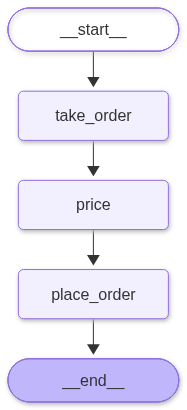

In [5]:
from IPython.display import Image

Image(graph.get_graph().draw_mermaid_png())

Read the picture from top to bottom. A run enters at `__start__`, passes through `take_order`, `price` and
`place_order` in the order of our edges, and leaves at `__end__`. Every arrow is solid: a solid arrow is always
followed.

### Run the graph

`graph.invoke(state)` runs the graph from `START` to `END` and returns the state at the end.

In [6]:
result = graph.invoke({"size": "medium", "extras": []})

print(result)

🍕 ORDER PLACED: medium with ['tomato sauce', 'mozzarella'], $11.00
{'size': 'medium', 'extras': [], 'toppings': ['tomato sauce', 'mozzarella'], 'price': 11.0, 'status': 'in the oven'}


The same `ORDER PLACED` line and the same five keys as our run by hand. This time we made none of the three calls
and wrote no `update`. LangGraph called each node with the current state and merged what the node returned.

### Watch the graph run step by step

`invoke` shows only the end. `graph.stream(state, stream_mode="updates")` hands us one item for each node as it
finishes: the node's name and the update it returned. We order a large this time.

In [7]:
for step in graph.stream({"size": "large", "extras": []}, stream_mode="updates"):
    print(step)

{'take_order': {'toppings': ['tomato sauce', 'mozzarella']}}
{'price': {'price': 14.0}}
🍕 ORDER PLACED: large with ['tomato sauce', 'mozzarella'], $14.00
{'place_order': {'status': 'in the oven'}}


Three steps, in the order of the edges, with the `ORDER PLACED` line printed by `place_order` while it ran.

**Notice** how small each update is. `price` returned `{'price': 14.0}` and nothing else. It did not pass the size
or the toppings along, and `place_order` could still print them, because they were in the state. A node reads
whatever it needs from the state and returns only what it changes.

**Checkpoint A.** Run by hand and run as a graph, the medium order prints one `ORDER PLACED` line and ends with
five keys, `price` 11.0 and `status` `in the oven`. The graph's nodes are `__start__`, `take_order`, `price`,
`place_order` and `__end__`. The stream shows three steps, one per node.

---

## Part B: Merge two nodes' updates to one key with a reducer

A customer wants mushrooms and olives. The price already counts them, because `price` reads `extras`. Nothing
puts them on the pizza yet. We add a node for that, `add_extras`, between `take_order` and `price`. It returns the
extras as toppings.

The lines marked `# new` are the only ones that differ from Part A. Before you run the cell: what will the
`toppings` list hold when the order reaches the kitchen?

In [8]:
def add_extras(order):
    return {"toppings": order["extras"]}


builder = StateGraph(Order)

builder.add_node("take_order", take_order)
builder.add_node("add_extras", add_extras)      # new
builder.add_node("price", price)
builder.add_node("place_order", place_order)

builder.add_edge(START, "take_order")
builder.add_edge("take_order", "add_extras")    # new
builder.add_edge("add_extras", "price")         # new
builder.add_edge("price", "place_order")
builder.add_edge("place_order", END)

graph = builder.compile()

for step in graph.stream({"size": "medium", "extras": ["mushrooms", "olives"]}, stream_mode="updates"):
    print(step)

{'take_order': {'toppings': ['tomato sauce', 'mozzarella']}}
{'add_extras': {'toppings': ['mushrooms', 'olives']}}
{'price': {'price': 14.0}}
🍕 ORDER PLACED: medium with ['mushrooms', 'olives'], $14.00
{'place_order': {'status': 'in the oven'}}


Read the `ORDER PLACED` line: a medium with `['mushrooms', 'olives']`. The kitchen got a pizza with **no tomato
sauce and no mozzarella**. No error was raised, and the price, 14.00, is right.

The steps show what happened:

1. `take_order` returned `toppings` with the sauce and the cheese.
2. `add_extras` returned `toppings` again, with the mushrooms and the olives.
3. LangGraph merged the second update the way `dict.update` does: the new value **replaced** the old one.

**Important:** by default, a node's update replaces the value of a key. That is what we want for `price` or
`status`, where the newest value is the right one. It is wrong for a list that several nodes add to.

### A reducer says how to combine the old value with the new one

A **reducer** is a function with two arguments, the value already in the state and the value a node returned. It
returns what the state should hold next. For our list we want a reducer that joins two lists, and Python already
has that function: `operator.add`, which is `+` written as a function. We try it on the two lists from the run
above.

In [9]:
import operator

print(operator.add(["tomato sauce", "mozzarella"], ["mushrooms", "olives"]))

['tomato sauce', 'mozzarella', 'mushrooms', 'olives']


One list with all four toppings, the first list in front.

To make LangGraph use this function for `toppings`, we attach it to the key's type with `Annotated`.
`Annotated[list, operator.add]` reads: *a list, and combine updates to it with `operator.add`*. The other keys
keep the default and are replaced.

In [10]:
from typing import Annotated


class Order(TypedDict):
    size: str
    extras: list
    toppings: Annotated[list, operator.add]     # the only line that changed
    price: float
    status: str

The nodes and the edges stay as they were. We build the graph again on the new state and send the same order.

In [11]:
builder = StateGraph(Order)

builder.add_node("take_order", take_order)
builder.add_node("add_extras", add_extras)
builder.add_node("price", price)
builder.add_node("place_order", place_order)

builder.add_edge(START, "take_order")
builder.add_edge("take_order", "add_extras")
builder.add_edge("add_extras", "price")
builder.add_edge("price", "place_order")
builder.add_edge("place_order", END)

graph = builder.compile()

for step in graph.stream({"size": "medium", "extras": ["mushrooms", "olives"]}, stream_mode="updates"):
    print(step)

{'take_order': {'toppings': ['tomato sauce', 'mozzarella']}}
{'add_extras': {'toppings': ['mushrooms', 'olives']}}
{'price': {'price': 14.0}}
🍕 ORDER PLACED: medium with ['tomato sauce', 'mozzarella', 'mushrooms', 'olives'], $14.00
{'place_order': {'status': 'in the oven'}}


The two nodes returned exactly what they returned before. The difference is in the `ORDER PLACED` line: the pizza
now has `['tomato sauce', 'mozzarella', 'mushrooms', 'olives']`. LangGraph called `operator.add` with the list in
the state and the list from `add_extras`, and kept the result.

### Lesson to Remember

A node returns only what it changed, and the state's type decides how that change is merged:

| The key is declared as | Two nodes return `toppings` | The state ends with |
|---|---|---|
| `list` | sauce and mozzarella, then mushrooms and olives | mushrooms and olives |
| `Annotated[list, operator.add]` | sauce and mozzarella, then mushrooms and olives | all four |

Notice that neither node changed between the two runs. The fix was one line in the state. In notebook 2 the state
is a conversation, a list of messages that every node adds to, so that list has a reducer as well.

**Checkpoint B.** Without a reducer the order is placed with `['mushrooms', 'olives']` only, at 14.00 dollars.
With `Annotated[list, operator.add]` it is placed with all four toppings, at the same price.

---

## Part C: Choose the next node with a route

So far every arrow is fixed: each order takes the same path. A program needs branches. Our pizza place has a rule:
an order over 18 dollars does not go straight to the kitchen. In this part such an order is refused. In Part D we
do better and ask the customer.

A **conditional edge** runs a function of ours after a node and goes to whichever node the function names. We call
that function a **route**. It takes the state and returns the name of the next node. `refuse` is the node for
orders over the limit.

In [12]:
ASK_ABOVE = 18.00


def route(order):
    if order["price"] > ASK_ABOVE:
        return "refuse"
    return "place_order"


def refuse(order):
    return {"status": "not placed: over 18 dollars"}

`route` is an ordinary function, so we can call it by hand with a cheap order and an expensive one before any
graph uses it.

In [13]:
print(route({"price": 12.50}))
print(route({"price": 20.00}))

place_order
refuse


`place_order` for 12.50 dollars and `refuse` for 20.00.

Now the graph. One line replaces the fixed edge from `price` to `place_order`:

```python
builder.add_conditional_edges("price", route, ["refuse", "place_order"])
```

It reads: *after `price`, call `route` and go where it says*. The list names the nodes `route` can return, so
that the drawing can show them.

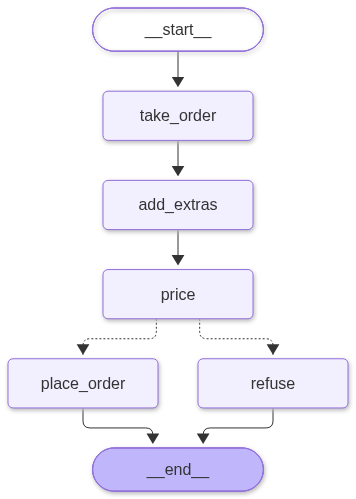

In [14]:
builder = StateGraph(Order)

builder.add_node("take_order", take_order)
builder.add_node("add_extras", add_extras)
builder.add_node("price", price)
builder.add_node("refuse", refuse)                                          # new
builder.add_node("place_order", place_order)

builder.add_edge(START, "take_order")
builder.add_edge("take_order", "add_extras")
builder.add_edge("add_extras", "price")
builder.add_conditional_edges("price", route, ["refuse", "place_order"])    # new
builder.add_edge("refuse", END)                                             # new
builder.add_edge("place_order", END)

graph = builder.compile()

Image(graph.get_graph().draw_mermaid_png())

Two arrows leave `price`, and they are **dotted**. A dotted arrow is conditional: a run follows one of them, the
one `route` names. The solid arrows are followed every time.

We send two orders: a medium with mushrooms, and a large with four extras for a party.

In [15]:
small_order = graph.invoke({"size": "medium", "extras": ["mushrooms"]})
print("price:", small_order["price"], "| status:", small_order["status"])

PARTY = {"size": "large", "extras": ["mushrooms", "olives", "peppers", "onions"]}

party_order = graph.invoke(PARTY)
print("price:", party_order["price"], "| status:", party_order["status"])

🍕 ORDER PLACED: medium with ['tomato sauce', 'mozzarella', 'mushrooms'], $12.50
price: 12.5 | status: in the oven
price: 20.0 | status: not placed: over 18 dollars


The medium costs 12.50 dollars, so `route` returned `place_order`: one `ORDER PLACED` line, and the status is
`in the oven`. The party pizza costs 14.00 plus four times 1.50, which is 20.00 dollars. `route` returned
`refuse`, no `ORDER PLACED` line was printed for it, and its status says why.

**Key lesson:** no model chose the path. `route` is an `if` in our own code, and it runs the same way every
time. A rule that must always hold belongs in an edge, where we can read it and test it.

**Checkpoint C.** `route` returns `place_order` for 12.50 and `refuse` for 20.00. The drawing has two dotted
arrows leaving `price`. The medium order is placed; the party order ends with the status
`not placed: over 18 dollars` and prints no `ORDER PLACED` line.

---

## Part D: Pause in a node with `interrupt` and resume with `Command`

Refusing a customer who wants a bigger pizza is poor business. A person at the counter would ask: *this comes to
20 dollars, shall I go ahead?* The answer may come at once, or after the customer has called home. Our program
should stop at the question and start again from the same place when the answer arrives.

LangGraph's `interrupt(value)` does the stopping. Called inside a node, it stops the run at that line and hands
`value` to the code that called the graph. `ask_first` takes the place of `refuse`.

In [16]:
from langgraph.types import interrupt


def ask_first(order):
    answer = interrupt(f"This order comes to ${order['price']:.2f}. Go ahead?")
    return {"approved": answer}

Read `ask_first` as two halves:

- **Up to `interrupt(...)`:** the run stops and the question goes out.
- **After it:** when the run is resumed with an answer, `interrupt(...)` returns that answer, and the node saves it
  in the state under `approved`.

Two more small changes. `route` now sends big orders to `ask_first`. A second route, `after_asking`, reads the
answer: on a yes the order goes to the kitchen, on a no the run ends. The state gets one more key, `approved`.

In [17]:
class Order(TypedDict):
    size: str
    extras: list
    toppings: Annotated[list, operator.add]
    price: float
    approved: bool      # new
    status: str


def route(order):
    if order["price"] > ASK_ABOVE:
        return "ask_first"
    return "place_order"


def after_asking(order):
    if order["approved"]:
        return "place_order"
    return END

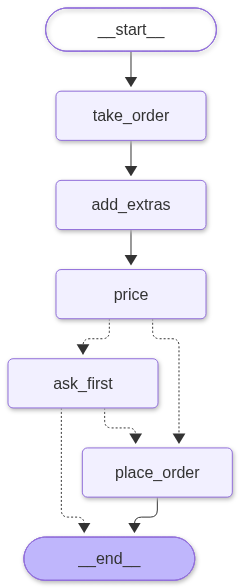

In [18]:
builder = StateGraph(Order)

builder.add_node("take_order", take_order)
builder.add_node("add_extras", add_extras)
builder.add_node("price", price)
builder.add_node("ask_first", ask_first)                                            # new
builder.add_node("place_order", place_order)

builder.add_edge(START, "take_order")
builder.add_edge("take_order", "add_extras")
builder.add_edge("add_extras", "price")
builder.add_conditional_edges("price", route, ["ask_first", "place_order"])
builder.add_conditional_edges("ask_first", after_asking, ["place_order", END])      # new
builder.add_edge("place_order", END)

graph = builder.compile()

Image(graph.get_graph().draw_mermaid_png())

`ask_first` sits between `price` and `place_order`, with dotted arrows in and out: an order reaches it only when
it costs more than 18 dollars, and leaves it for the kitchen only on a yes.

### The run stops at the question

We send the party order again.

In [19]:
paused = graph.invoke(PARTY)

print("keys:    ", list(paused))
print("question:", paused["__interrupt__"][0].value)

keys:     ['size', 'extras', 'toppings', 'price', '__interrupt__']
question: This order comes to $20.00. Go ahead?


No `ORDER PLACED` line. The run went through `take_order`, `add_extras` and `price`, entered `ask_first`, and
stopped there. What `invoke` returned is the state so far, with one more key:

- `__interrupt__` is a list with one `Interrupt` object. Its `.value` is what we passed to `interrupt(...)`: the
  question, with the price filled in.
- `status` and `approved` are missing, because no node has written them yet.

### Resuming needs a place where the paused run is kept

The customer says yes. To continue a paused run we call `invoke` again, and in place of a state we pass
`Command(resume=...)` with the answer. We wrap the call in `try` so that an error is printed and the notebook
carries on.

In [20]:
from langgraph.types import Command

try:
    graph.invoke(Command(resume=True))
except RuntimeError as error:
    print(type(error).__name__, "|", error)

RuntimeError | Cannot use Command(resume=...) without checkpointer


`Cannot use Command(resume=...) without checkpointer`. The run stopped, and nothing kept it. `invoke` returned,
and the half-finished order was only in the dictionary we printed. To resume, LangGraph needs two things:

- A **checkpointer**, which saves the state after every step. `InMemorySaver` keeps it in a Python dictionary, in
  the memory of this notebook's kernel.
- A **thread id**, a name for one run, so that the checkpointer can tell this order from every other one. It
  travels in a `config` dictionary that we pass with every call. `configurable` is the key under which LangGraph
  looks for it.

We compile the same builder again with a checkpointer, and send the party order under the thread id `order-17`.

In [21]:
from langgraph.checkpoint.memory import InMemorySaver

graph = builder.compile(checkpointer=InMemorySaver())

config = {"configurable": {"thread_id": "order-17"}}

paused = graph.invoke(PARTY, config)
print("question:", paused["__interrupt__"][0].value)

question: This order comes to $20.00. Go ahead?


The same question, and this time the paused run is saved. `graph.get_state(config)` asks the checkpointer what it
holds for the thread:

- `.values` is the state so far.
- `.next` names the node that runs when the thread continues.
- `.interrupts` lists what is waiting for an answer.

In [22]:
saved = graph.get_state(config)

print("price so far:", saved.values["price"])
print("next node:   ", saved.next)
print("waiting on:  ", [stop.value for stop in saved.interrupts])

price so far: 20.0
next node:    ('ask_first',)
waiting on:   ['This order comes to $20.00. Go ahead?']


The checkpointer holds an order of 20.00 dollars that will continue at `ask_first` and is waiting on our
question. The customer can take as long as they like: nothing is running.

### Resume with the answer

The same `Command(resume=True)` as before, now with the `config` that names the thread.

In [23]:
done = graph.invoke(Command(resume=True), config)

print("approved:", done["approved"], "| status:", done["status"])
print("next node:", graph.get_state(config).next)

🍕 ORDER PLACED: large with ['tomato sauce', 'mozzarella', 'mushrooms', 'olives', 'peppers', 'onions'], $20.00
approved: True | status: in the oven
next node: ()


Now the `ORDER PLACED` line is printed, with all six toppings and 20.00 dollars. What happened, step by step:

1. LangGraph loaded the thread `order-17` from the checkpointer.
2. It ran `ask_first` again from its first line. This time `interrupt(...)` did not stop the run: it returned
   our answer, `True`.
3. The node returned `{"approved": True}`, `after_asking` chose `place_order`, and the order went to the kitchen.
4. `next` is empty: the thread has nothing left to run.

**Important:** look at step 2. On a resume the node starts again **from its first line**, not from the middle.
`ask_first` has nothing before its `interrupt`, so nothing ran twice. Code placed before an `interrupt` runs
twice: once before the pause and once on the resume. Bonus lab B1 is about that.

**Checkpoint D.** Without a checkpointer the run stops at the question, and a resume raises
`Cannot use Command(resume=...) without checkpointer`. With `InMemorySaver` and the thread id `order-17`,
`get_state` shows `next` as `('ask_first',)` and the question waiting. After `Command(resume=True)` the
`ORDER PLACED` line is printed with six toppings, `approved` is `True` and `next` is empty.

---

## Part E: Make one node a model call

Every node so far is plain Python, and every order arrived as a tidy dictionary. Customers write sentences:

> There are four of us and we are starving. Your biggest pizza, with mushrooms, olives, peppers and onions, please!

Turning that sentence into a `size` and a list of `extras` is a job for a language model. A node is a Python
function, and a Python function can call a model. So the model gets one node, and the rest of the graph stays as
it is.

### A chat model, called once

`ChatOpenAI`, from the `langchain-openai` package, is LangChain's object for an OpenAI model. We give it the model
name and the reasoning effort from `models.env`. The reasoning effort is how much reasoning the model does before
it replies; here it is `none`. We also set a limit of 60 seconds per request and at most two retries, so that a
request that gets stuck fails within minutes and does not freeze the cell. `invoke` sends a message and returns the reply, and `.text` is the reply's words.

In [24]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model=MODEL, reasoning_effort=EFFORT, timeout=60, max_retries=2)

reply = llm.invoke("Write a five-word slogan for a pizza place.")

print(reply.text)

Hot, cheesy, fresh from the oven.


In our run the slogan was *Hot, cheesy, fresh from the oven.* Yours will differ: the model writes a new one each time.

Count the words in ours: we asked for five and got six. A model's free text follows an instruction loosely, which is why
the next step asks for a form.

### Ask the model for an order form

A slogan can be any text. Our graph needs two exact keys. We describe them as a small class, `OrderForm` (a
Pydantic model: a class that lists its fields and checks their types), with the type of each field:

- `size` is `Literal["small", "medium", "large"]`: one of these three words and nothing else, so `BASE_PRICE[size]`
  always finds a price.
- `extras` is a list of strings.

`llm.with_structured_output(OrderForm)` returns a copy of the model whose reply is an `OrderForm` object, not
free text.

In [25]:
from typing import Literal
from pydantic import BaseModel


class OrderForm(BaseModel):
    """What the customer asked for."""
    size: Literal["small", "medium", "large"]
    extras: list[str]


order_reader = llm.with_structured_output(OrderForm)

REQUEST = ("There are four of us and we are starving. "
           "Your biggest pizza, with mushrooms, olives, peppers and onions, please!")

form = order_reader.invoke(REQUEST)

print(repr(form))

OrderForm(size='large', extras=['mushrooms', 'olives', 'peppers', 'onions'])


An `OrderForm` with two fields. The model read *your biggest pizza* as `large`, and listed the four extras that the sentence names.

### Put the model call in a node

`read_request` is a node like the others: it takes the state and returns what it adds. It reads the customer's
sentence from a new key, `request`, calls the model, and returns `size` and `extras`. It runs first. From
`take_order` on, the graph is Part D's, line for line.

In [26]:
class Order(TypedDict):
    request: str        # new: the customer's own words
    size: str
    extras: list
    toppings: Annotated[list, operator.add]
    price: float
    approved: bool
    status: str


def read_request(order):
    form = order_reader.invoke(order["request"])
    return {"size": form.size, "extras": form.extras}

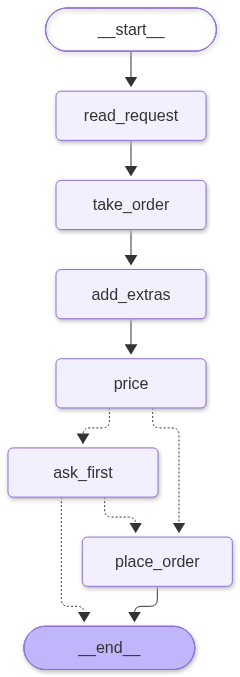

In [27]:
builder = StateGraph(Order)

builder.add_node("read_request", read_request)      # new
builder.add_node("take_order", take_order)
builder.add_node("add_extras", add_extras)
builder.add_node("price", price)
builder.add_node("ask_first", ask_first)
builder.add_node("place_order", place_order)

builder.add_edge(START, "read_request")             # new
builder.add_edge("read_request", "take_order")      # new
builder.add_edge("take_order", "add_extras")
builder.add_edge("add_extras", "price")
builder.add_conditional_edges("price", route, ["ask_first", "place_order"])
builder.add_conditional_edges("ask_first", after_asking, ["place_order", END])
builder.add_edge("place_order", END)

graph = builder.compile(checkpointer=InMemorySaver())

Image(graph.get_graph().draw_mermaid_png())

One more node at the top. Nothing in the drawing says that `read_request` calls a model: to the graph it is a
function like the others.

We send the customer's sentence under a new thread id.

In [28]:
config = {"configurable": {"thread_id": "order-18"}}

paused = graph.invoke({"request": REQUEST}, config)

print("size:    ", paused["size"])
print("extras:  ", paused["extras"])
print("question:", paused["__interrupt__"][0].value)

size:     large
extras:   ['mushrooms', 'olives', 'peppers', 'onions']
question: This order comes to $20.00. Go ahead?


`read_request` filled in the size and the extras, and the rest of the graph did its work as before. A large with four extras costs 20.00 dollars, which is over the limit, so the run stopped at `ask_first` with our question.

The customer says yes.

In [29]:
done = graph.invoke(Command(resume=True), config)

print("status:", done["status"])

🍕 ORDER PLACED: large with ['tomato sauce', 'mozzarella', 'mushrooms', 'olives', 'peppers', 'onions'], $20.00
status: in the oven


One `ORDER PLACED` line: a large with the sauce, the cheese and the four extras, at 20.00 dollars.

The whole run made **one** model call, in `read_request`: it is the only node that calls the model, and the resume
started again at `ask_first`, not at the top. Everything after `read_request` was our Python: the toppings, the
price, the rule about big orders, the question and the kitchen.

**Key lesson:** the model wrote the order, and our code decided what happened to it. The rule that sends a big
order to the question is an edge in our graph, so no reply from the model can skip it.

**Checkpoint E.** `order_reader` returns an `OrderForm` with the size `large` and the extras the sentence names
(ours: four). The graph stops with the question *This order comes to \$20.00. Go ahead?* and, after
`Command(resume=True)`, prints one `ORDER PLACED` line.

---

## Part F: Find the same kind of graph inside `create_agent`

In Part E our edges fixed the path, and the model filled in one step. An **agent** turns that around: the model's
reply decides what runs next. The model asks for a tool, reads the result, and then asks for another tool or
writes the answer.

LangChain's `create_agent` builds an agent from a model and a list of tools. A tool is a Python function with type
hints and a docstring. From these, LangChain writes the description that the model reads. We give the agent one
tool, a function that quotes a price.

In [30]:
from langchain.agents import create_agent


def quote_price(size: str, extras: list[str]) -> float:
    """Work out the price of a pizza in US dollars from its size (small, medium or large) and its extra toppings."""
    print(f"🧮 TOOL CALLED: quote_price({size}, {extras})")
    return BASE_PRICE[size] + EXTRA_PRICE * len(extras)


agent = create_agent(
    llm,
    [quote_price],
    system_prompt="You answer questions about pizza prices. Use quote_price for every price. Answer in one sentence.",
)

print(type(agent).__name__)
print(list(agent.get_graph().nodes))

CompiledStateGraph
['__start__', 'model', 'tools', '__end__']


`create_agent` returned a `CompiledStateGraph`, the same class as our pizza graph. It has two nodes between
`__start__` and `__end__`: `model` and `tools`. We can draw it the same way.

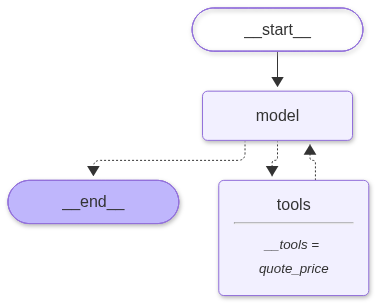

In [31]:
Image(agent.get_graph().draw_mermaid_png())

How to read the drawing:

- `model` calls the model. The small line under `tools` lists the tools that node can run.
- Two dotted arrows leave `model`. After every model call a route reads the reply: if it asks for a tool the run
  goes to `tools`, and if not it goes to `__end__` with the answer. It is the same idea as our `route`, written
  for us.
- The arrow from `tools` back to `model` is new. Our pizza graph only went forward. This graph has a **loop**: a
  tool's result goes back to the model, which can ask again.

We watch it run with `stream`, as in Part A. The state of this graph has one key, `messages`: the conversation so
far. We start it with one message, written as a dictionary with a `role` and a `content`. Each update holds the
messages a node added, and we print the last one.

LangGraph turns that dictionary into a message object, and the model's replies and the tools' results are message
objects too. A message's `.type` says who wrote it (`ai` for the model, `tool` for a tool's result), `.text` is
its words, and `.tool_calls` is the list of tools the model asks for, each with a `name` and `args`.

In [32]:
question = {"messages": [{"role": "user", "content": "How much is a large with mushrooms and olives?"}]}

for step in agent.stream(question, stream_mode="updates"):
    for node, update in step.items():
        message = update["messages"][-1]
        if message.type == "ai" and message.tool_calls:
            print(node, "asks for", message.tool_calls[0]["name"], message.tool_calls[0]["args"])
        else:
            print(node, "returns ", message.text)

model asks for quote_price {'size': 'large', 'extras': ['mushrooms', 'olives']}
🧮 TOOL CALLED: quote_price(large, ['mushrooms', 'olives'])
tools returns  17.0


model returns  A large pizza with mushrooms and olives costs $17.00.


Three steps, read from the top:

1. `model` did not answer. It asked for `quote_price` with the size `large` and the two extras.
2. `tools` ran our function, which printed the `TOOL CALLED` line, and returned 17.0.
3. `model` ran a second time, read that result, and wrote the answer: 17 dollars.

Nobody wrote an edge that says *call `quote_price` once and then answer*. The model's first reply asked for the
tool, so the route went to `tools`. Its second reply had no tool request, so the route went to `__end__`.

| | Our pizza graph (Part E) | The agent's graph |
|---|---|---|
| Who chooses the next node | our `route`, from the price | a route that reads the model's reply |
| Where the model is | one node at the start | the `model` node, on every turn of the loop |
| What the state holds | the order's keys | `messages`, the conversation |
| How a list in the state grows | `operator.add` on `toppings` | a reducer on `messages` |

Notebook 2 builds this second graph by hand at the Chinook support desk, and puts a step of our own inside the
loop: a pause before a refund.

**Checkpoint F.** `create_agent` returns a `CompiledStateGraph` with the nodes `__start__`, `model`, `tools` and
`__end__`. The stream shows `model` asking for `quote_price`, one `TOOL CALLED` line, `tools` returning 17.0, and
`model` returning the answer.

---

## What you can do now

- Write a program as a `StateGraph` with a state, nodes and edges, draw it with `draw_mermaid_png`, run it with
  `invoke` and watch it with `stream` (Part A).
- Say why a node's update replaces a value, and give a key a reducer with `Annotated` so that two nodes can add to
  it (Part B).
- Send a run down one of several paths with `add_conditional_edges` and a route written in plain Python (Part C).
- Stop a run inside a node with `interrupt`, give the graph a checkpointer and a thread id, read what is waiting
  with `get_state`, and resume with `Command(resume=...)` (Part D).
- Put a model call in one node of a graph whose path our code controls (Part E).
- Recognise the `model` node, the `tools` node and the loop in the graph that `create_agent` returns (Part F).

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `ValueError: Failed to reach https://mermaid.ink API while trying to render your graph` | the drawing cells send the graph's description to mermaid.ink, and the service could not be reached | check the internet connection and run the cell again; or run `print(graph.get_graph().draw_mermaid())`, which prints the same nodes and arrows as text (`-->` is a solid arrow, `-.->` a dotted one). Every other cell works without the drawing |
| `RuntimeError: Cannot use Command(resume=...) without checkpointer` | the graph was compiled without a checkpointer, so a paused run is not kept | compile with `checkpointer=InMemorySaver()` |
| `ValueError: Checkpointer requires one or more of the following 'configurable' keys: thread_id, checkpoint_ns, checkpoint_id` | a graph with a checkpointer was called without a `config` | pass `config` with a `thread_id` as the second argument of `invoke` |
| `KeyError: 'extras'` after a `Command(resume=...)` | the thread id in `config` has no paused run, so LangGraph started a new run with an empty state | resume with the same `config` the paused run was started with; notebook 2 looks at this case closely |

## Challenge

1. **Say no.** After Part E, `graph` begins with `read_request`. Go back to Part D's graph first: run the Part D cell that starts `builder = StateGraph(Order)` and adds the `ask_first` node, then run
   `graph = builder.compile(checkpointer=InMemorySaver())`. Send the party order (`PARTY`) to it under a new thread
   id, and answer the question with
   `Command(resume=False)`. Print `approved`, whether the result has a `status` key, and
   `graph.get_state(config).next`.

   Expected: no `ORDER PLACED` line, `approved` is `False`, there is no `status` key, and `next` is empty.

2. **Charge for delivery, and keep a receipt.** Start from the same graph, with no model node. Add a key `receipt`
   to the state, a list with the same reducer as
   `toppings`. Change `price` so that it also returns one receipt line, and add a node `add_delivery` after `price`
   that adds 2.50 dollars to the price and returns a second receipt line. Move the conditional edge so that `route`
   runs after `add_delivery`. Then order a medium and a large, each with mushrooms and olives.

   Expected: the medium is placed at 16.50 dollars with a receipt of two lines. The large comes to 19.50 dollars
   with delivery, so the graph now stops and asks first, although the pizza alone (17.00) is under the limit.

The worked solution, run with its outputs, is in `solved/10a_meet_langgraph_solution.ipynb`.

## Going further

- **LangGraph Studio.** LangGraph has a browser page that draws a graph and lets you step through a run. It is
  started with `langgraph dev`, which needs the `langgraph-cli[inmem]` package and a LangSmith API key (a free
  account), and the page itself is hosted by LangSmith. This repository installs neither, so the lab draws its
  graphs in the notebook.
- **Events while a run is in progress.** `graph.stream_events(..., version="v3")` reports a run as it happens,
  with its interrupts on the stream object. The documentation recommends it for applications; `invoke` and
  `__interrupt__`, which we used, do the same job in fewer lines.

## Resources

- [LangGraph overview](https://docs.langchain.com/oss/python/langgraph/overview): what LangGraph is for
- [Graph API](https://docs.langchain.com/oss/python/langgraph/graph-api): state, reducers, nodes, edges and
  conditional edges
- [Interrupts](https://docs.langchain.com/oss/python/langgraph/interrupts): `interrupt`, `Command(resume=...)` and
  the rule that a node starts again from its first line
- [Checkpointers](https://docs.langchain.com/oss/python/langgraph/checkpointers): `InMemorySaver`, threads and
  `get_state`
- [Streaming](https://docs.langchain.com/oss/python/langgraph/streaming): `stream` and its modes
- [LangChain agents](https://docs.langchain.com/oss/python/langchain/agents): `create_agent`
- [Structured output](https://docs.langchain.com/oss/python/langchain/structured-output): asking a model for an
  object with named fields
- [Run a local server](https://docs.langchain.com/oss/python/langgraph/local-server): `langgraph dev` and Studio

Next: [notebook 2, LangGraph at the Chinook desk](10b_langgraph_at_the_desk.ipynb).